# 00. Exploratory data analysis

Kaggle *Financial Sentiment Analysis*: financial news sentences labelled as `negative`, `neutral` or `positive`.

In [1]:
import pandas as pd

from itg_classification.config import FIGURES_DIR
from itg_classification.eda import (
    class_distribution,
    column_overview,
    conflicting_rows,
    conflicting_texts,
    duplicates_summary,
    imbalance_ratio,
    length_stats,
    pattern_shares,
    plot_class_distribution,
    plot_text_lengths,
    sample_per_class,
    text_lengths,
)
from itg_classification.load_data import load_dataset

pd.set_option("display.max_colwidth", 200)

## 1. Structure

In [2]:
df = load_dataset()
df.shape

(5842, 2)

In [3]:
df.head()

,text,label
0,"The GeoSolutions technology will leverage Benefon 's GPS solutions by providing Location Based Search Technology , a Communities Platform , location relevant multimedia content and a new and power...",positive
1,"$ESI on lows, down $1.50 to $2.50 BK a real possibility",negative
2,"For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year earlier , while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m .",positive
3,"According to the Finnish-Russian Chamber of Commerce , all the major construction companies of Finland are operating in Russia .",neutral
4,"The Swedish buyout firm has sold its remaining 22.4 percent stake , almost eighteen months after taking the company public in Finland .",neutral


In [4]:
column_overview(df)

,dtype,non_null,missing,blank
text,str,5842,0,0
label,str,5842,0,0


No missing or blank values: both columns are plain strings.

## 2. Duplicates

In [5]:
duplicates_summary(df)

rows                          5842
unique_texts                  5322
duplicate_rows                   6
duplicate_texts                520
normalized_duplicate_texts     520
conflicting_texts              514
dtype: int64

In [6]:
conflicting_texts(df).value_counts()

label
(negative, neutral)    514
Name: count, dtype: int64

In [7]:
conflicting_rows(df).head(6)

,text,label
3685,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",negative
4578,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",neutral
1488,"( ADP News ) - Feb 12 , 2009 - Finnish construction company Lemminkainen Oyj ( HEL : LEM1S ) said today its net profit decreased to EUR 63.5 million ( USD 81.1 m ) for 2008 from EUR 80.6 million f...",negative
3765,"( ADP News ) - Feb 12 , 2009 - Finnish construction company Lemminkainen Oyj ( HEL : LEM1S ) said today its net profit decreased to EUR 63.5 million ( USD 81.1 m ) for 2008 from EUR 80.6 million f...",neutral
1051,"( ADP News ) - Feb 4 , 2009 - Finnish broadband data communication systems and solutions company Teleste Oyj ( HEL : TLT1V ) said today its net profit decreased to EUR 5.5 million ( USD 7.2 m ) fo...",negative
740,"( ADP News ) - Feb 4 , 2009 - Finnish broadband data communication systems and solutions company Teleste Oyj ( HEL : TLT1V ) said today its net profit decreased to EUR 5.5 million ( USD 7.2 m ) fo...",neutral


- Only 6 rows are full duplicates (same text and label).
- 514 texts occur twice with different labels, and every one of them is labelled both `negative` and `neutral`.
- Normalizing case and whitespace finds no extra duplicates.

The conflicts are label noise between `negative` and `neutral`. They must be resolved before the split: otherwise the same text can land in train with one label and in test with another.

## 3. Class distribution

In [8]:
distribution = class_distribution(df)
distribution

,count,share
label,,
negative,860,0.147210
neutral,3130,0.535775
positive,1852,0.317015


In [9]:
imbalance_ratio(distribution)

3.63953488372093

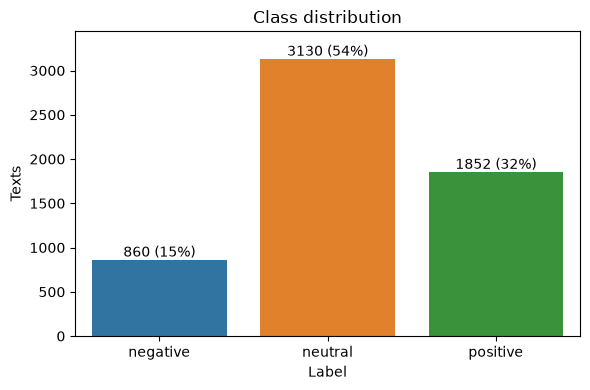

In [10]:
plot_class_distribution(df, FIGURES_DIR / "class_distribution.png");

Without the conflicting texts the minority class shrinks even more:

In [11]:
clean = df[~df["text"].isin(conflicting_texts(df).index)]
class_distribution(clean)

,count,share
label,,
negative,346,0.071874
neutral,2616,0.543415
positive,1852,0.384711


- `neutral` is more than half of the data, `negative` is about 15%: the largest class outnumbers the smallest one 3.6 times.
- Accuracy would be misleading: always predicting `neutral` already gives 54%. Macro F1 treats every class equally, so it is the main metric.
- The split must be stratified to keep these shares in train and test.
- Dropping the conflicting texts would leave only 346 `negative` examples (7%), so how we resolve the conflicts matters a lot for this class.

## 4. Text lengths

In [12]:
length_stats(df).round(1)

count   mean   std   min   25%    50%    75%    max
unit  label                                                         
chars negative   860.0  105.3  51.8  12.0  66.0   94.0  132.2  296.0
      neutral   3130.0  123.1  56.9   9.0  79.0  114.0  158.0  315.0
      positive  1852.0  112.2  56.4  10.0  67.0  100.0  145.2  298.0
words negative   860.0   19.3  10.3   2.0  11.0   17.0   25.0   56.0
      neutral   3130.0   22.1  10.0   2.0  15.0   21.0   28.0   81.0
      positive  1852.0   19.9  10.6   2.0  11.0   18.0   27.0   57.0

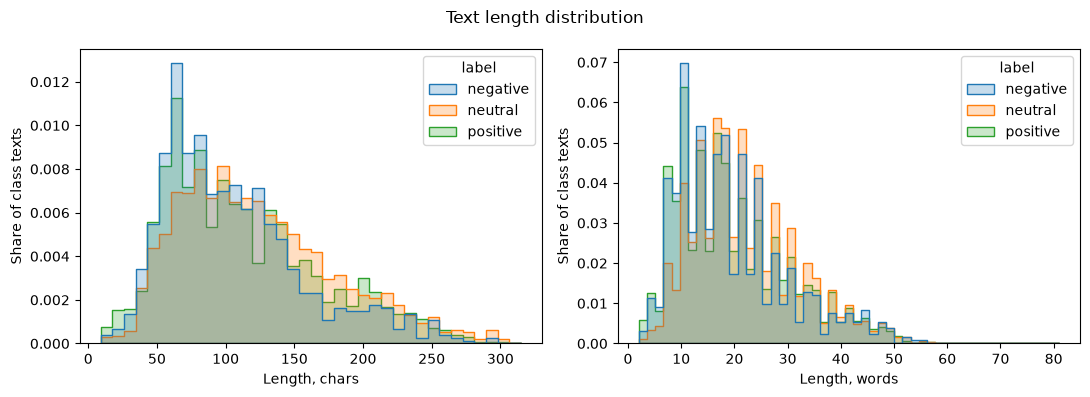

In [13]:
plot_text_lengths(df, FIGURES_DIR / "text_length_distribution.png");

The shortest and the longest texts:

In [14]:
lengths = text_lengths(df["text"])
df.loc[lengths["chars"].nsmallest(8).index]

,text,label
2145,Welcome !,neutral
863,long $AAPL,positive
3520,Long $PCLN,positive
921,It 's not .,neutral
98,$TSLA recall,negative
157,R&D Loan ) .,neutral
1518,Long $X 24.62,positive
1720,$DCTH Near HOD,positive


In [15]:
df.loc[lengths["chars"].nlargest(3).index]

,text,label
3800,"Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 , N71 , E90 , E71 , E70 , E66 , E65 , E62 , E61-E61i , E60 ,...",neutral
5179,"Our customers come from the following countries : UK , USA , Spain , France , Italy , Germany , China , Sweden , Norway , Netherlands , Austria , Belgium , Switzerland , Czech Republic , Serbia , ...",neutral
1708,"POYRY PLC Additional information by : Martin Kuzaj , President , Industry Business Group , Finland Tel. +358 10 33 21179 Sanna Paivaniemi , Director , Investor Relations , Poyry PLC , Finland Tel....",neutral


In [16]:
(lengths["words"] <= 3).sum()

np.int64(26)

- Texts are short single sentences: median 107 characters or 19 words, never longer than 315 characters or 81 words. No truncation or splitting is needed.
- `neutral` texts are a bit longer (median 21 words against 17-18), but the distributions overlap almost completely, so length alone is a weak feature.
- 26 texts have 3 words or fewer, like `Welcome !` or `long $AAPL`. They carry little signal, but they are valid examples, so we keep them.
- The longest texts are lists of products or countries and contact details, not outliers to remove.
- Two styles are visible: tweets with cashtags like `$AAPL`, and news sentences with spaces around punctuation like `Benefon 's` and `2009 ,`. We look at it closer in the examples.

## 5. Examples per class

In [17]:
sample_per_class(df, n=5)

text
label    row                                                                                                                                               
negative 4959                                                            `` Adjustment to the fall in price level , in contrast , has been less effective .
         4161                                                                         Hard to find new buyers of $TSLA at 250.  Shorts continue to pile in.
         895                        Finnlines estimated in its annual general meeting that 2008 will be financially a tough year due to large investments .
         1463                                                                                    Kingfisher takeover of Mr Bricolage could hit a brick wall
         2644                                                        18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
neutral  3151  The fixed acquisition price amounts to NOK 70 ( approximately EUR 8.7 ) million and additional price NOK 15 ( EUR 1.8 ) million at maximum .
         4724                            The Finnish company previously said its operating result will be lower than the break-even posted a year earlier .
         337                                                                    Westpac Banking Corp - Is to issue a benchmark , 3 year FRN deal in Euros .
         2763                                                   The Insolvency Act regulates the amount of debt that borrowers are permitted to write off .
         5485                                              Net cash from operating activities was a negative EUR 0.3 mn , compared to EUR 30.9 mn in 2009 .
positive 733                                                                            Sales VAT inclusive expanded by 19 percent , to 351 million euros .
         1358                                                                $FB Big Money Is Pouring Into Facebook From All Directions;http://stks.co/sOwG
         3930                                            According to CEO Matti Karppinen , Frozen Foods posted a good result in 2010 , as it did in 2009 .
         5348                                                                                           Irish housebuilder Cairn Homes plans London listing
         1242                                             Ruukki 's order book at the end of 2010 was 30 % up year-on-year and 10 % up quarter-on-quarter .

Share of texts with a cashtag (`$AAPL`) or a link, per class:

In [18]:
pattern_shares(df).round(2)

label,negative,neutral,positive
cashtag,0.25,0.01,0.23
url,0.09,0.00,0.09


- `negative` and `positive` are clear in most examples: falling profit, a leakage at a mine, sales up 19%, order book up 30%.
- `neutral` is factual news without a direction: an acquisition price, a bond issue, a law.
- Some `neutral` texts still contain sentiment words, like *operating result will be lower* or *a negative EUR 0.3 mn*. Together with the negative/neutral conflicts from section 2 this border will be the hardest for the model.
- The data mixes two sources. News sentences have spaces around punctuation (`Ruukki 's`, `30 %`). Tweets have cashtags, links and slang (`Shorts continue to pile in`).
- A quarter of `negative` and `positive` texts have a cashtag, but only 1% of `neutral` ones: the tweets are almost never neutral. A model can learn "cashtag means not neutral" as a shortcut, so we check it in the error analysis.
- Links like `http://stks.co/sOwG` carry no sentiment and should be removed or replaced during preprocessing.

## 6. Summary

**Task.** Three-class sentiment classification of short financial texts: `negative`, `neutral`, `positive`.

**Structure.** 5,842 rows, two string columns, no missing or blank values. Texts are single sentences, median 19 words, at most 81.

**Quality issues:**

1. **Label conflicts.** 514 texts appear twice, once as `negative` and once as `neutral`. That is 60% of all `negative` rows. Plus 6 exact duplicate rows.
2. **Class imbalance.** `neutral` 54%, `positive` 32%, `negative` 15% (3.6 : 1).
3. **Two sources.** Tokenized news sentences (`Ruukki 's`, `30 %`) and tweets with cashtags, links and slang.
4. **Source shortcut.** Cashtags occur in about a quarter of `negative` and `positive` texts and in 1% of `neutral` ones.

**Decisions for the next days:**

- Resolve the duplicates and conflicts **before** the train/test split, otherwise the same text leaks into both.
- Use **macro F1** as the main metric: a constant `neutral` prediction already gets 54% accuracy.
- Split with **stratification** by label.
- In preprocessing, remove links and undo the news tokenization (`'s`, `%`, spaces before punctuation).
- In the error analysis, check the `negative`/`neutral` border and whether the model relies on cashtags.